Libraries and Variables Used

In [1]:
import os
os.chdir(r'C:\Users\Jryle\Documents\Projects\Monte_Carlo')

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from pricing import *

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from numpy.polynomial import polynomial as P
from pricing import *

import yfinance as yf
import datetime

In [2]:
S0 = 100                    #current stock price
K = 105                     #strike price
T = 1.0                     #time to maturity (yrs)
r = 0.05                    #risk-free rate
sigma = 0.2                 #volatility
n_simulations = 100000      #number of simulations
n_steps = 50                #number of time steps

## Black-Scholes Call Option

This function uses the Black-Scholes formula to estimate the fair value of a European call option given parameters (current stock price, strike price, time until expiration (yrs), risk-free rate, and volatility). This is a non-simulated solution.

I am using this as a control to compare the performance of the Monte Carlo simulation later in this notebook. If the simulation converges to the calculated Black-Scholes value as the number of simulated paths increase, then the program functions as intended.

In [3]:
bs_price = black_scholes_call(S0, K, T, r, sigma)
print(f"Black-Scholes price: {bs_price:.4f}")

Black-Scholes price: 8.0214


## Monte Carlo Call Option Simulation

This function simulates many possible final stock prices to estimate the value of a European call option. A random shock is generated from a standard normal distribution for each path. Using this, the stock's volatility and the risk-free rate, the ending stock price of each path can be simulated. Each option's payoff is then calculated, averaged, and then discounted back to today's value to estimate the fair price.

In [4]:
mc_price = monte_carlo_call(S0, K, T, r, sigma, n_simulations)
print(f"Monte Carlo price: {mc_price:.4f}")
print(f"Difference from Black-Scholes: {abs(mc_price - bs_price):.4f}")    #print difference between the two methods

Monte Carlo price: 7.9496
Difference from Black-Scholes: 0.0718


The chart below graphs 20 points, each representing the average payoff across n simulations, where n increases along the x-axis. The number of simulations for each point is evenly spaced out on a logarithmic scale.

As predicted above, when the number of simulations increase, the average simulated fair price for the call option converges to the value calculated by the Black-Scholes formula.

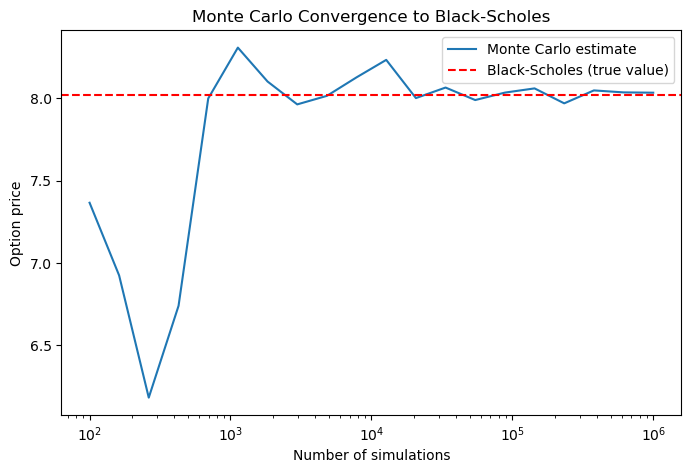

In [5]:
sim_counts = np.logspace(2, 6, 20).astype(int)                                               #gets range, 20 points equally spaced along log scale between 100 and 1,000,000
prices = [monte_carlo_call(S0, K, T, r, sigma, n) for n in sim_counts]                       #runs Monte Carlo simulation for each count with n simulations in each

#neatly plot the 20 points found with the monte carlo method
plt.figure(figsize=(8,5))
plt.plot(sim_counts, prices, label='Monte Carlo estimate')
plt.axhline(bs_price, color='red', linestyle='--', label='Black-Scholes (true value)')
plt.xscale('log')
plt.xlabel('Number of simulations')
plt.ylabel('Option price')
plt.title('Monte Carlo Convergence to Black-Scholes')                                       #save plot
plt.legend()
plt.savefig('../images/price_convergence_plot.png', dpi=150, bbox_inches='tight')
plt.show()

The Monte Carlo Simulation's error is expected to shrink proportionally to   1/sqrt(n) as the number of simulations increases, according to the Law of Large Numbers. The below chart, showing absolute error vs. number of simulations (both on a log scale), demonstrates a general downward, negative trend that is consistent with this relationship. Note that there is always noise due to the independent, random nature of of each batch of simulations.

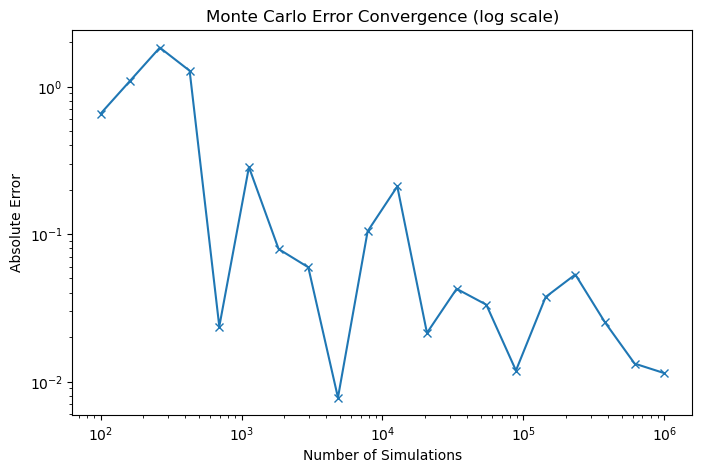

In [6]:
#neatly plot the error convergence
err = np.abs(np.array(prices) - bs_price)
plt.figure(figsize=(8,5))
plt.loglog(sim_counts, err, marker ='x')
plt.xlabel('Number of Simulations')
plt.ylabel('Absolute Error')
plt.title('Monte Carlo Error Convergence (log scale)')
plt.show()

## Applying Antithetic Variance Reduction

The Monte Carlo simulation can be further improved using antithetic variates to reduce variance. For every random shock Z randomly generated, a second path is generated with shock -Z. By pairing the two negatively correlated shocks in this manner, extreme outcomes partially cancel when averaged. This generates more precise data with the same number of paths while needing only half the number of independently random draws.

To test the variance reduction technique, both the plain and antithetic Monte Carlo simulations were run 200 times each, with 1,000 simulations in each run. The resulting standard deviations show that the plain Monte Carlo method typically produces larger standard deviations than the antithetic method which confirms that antithetic variates reduce the variance of the price estimate.

In [7]:
plain = [monte_carlo_call(S0, K, T, r, sigma, 1000) for _ in range(200)]                       #run each method 200 times, 1000 simulations per run
antithetic = [antithetic_monte_carlo_call(S0, K, T, r, sigma, 1000) for _ in range(200)]

print(f"Standard deviation of plain Monte Carlo: {np.std(plain):.6f}")                         #print results`
print(f"Standard deviation of antithetic Monte Carlo: {np.std(antithetic):.6f}")


Standard deviation of plain Monte Carlo: 0.435222
Standard deviation of antithetic Monte Carlo: 0.338108


The histogram below shows two separate data sets, one representing the simulations from the plain Monte Carlo (blue) and one representing the antithetic Monte Carlo (red). The plain data produces a wider and shorter cluster of data compared to the taller and thinner cluster from the antithetic data. The narrower spread confirms that antithetic variates were successful in reducing the variance of the price estimate.

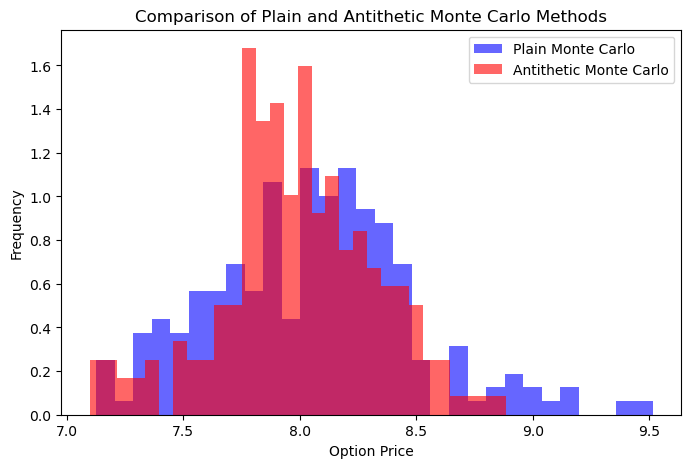

In [8]:
#neatly plot overlapping histograms for each method's data
plt.figure(figsize=(8, 5))
plt.hist(plain, bins=30, alpha=0.6, label='Plain Monte Carlo', color='blue', density=True)
plt.hist(antithetic, bins=30, alpha=0.6, label='Antithetic Monte Carlo', color='red', density=True)
plt.xlabel('Option Price')
plt.ylabel('Frequency')
plt.title('Comparison of Plain and Antithetic Monte Carlo Methods')
plt.legend()
plt.savefig('../images/antithetic_comparison.png', dpi=150, bbox_inches='tight')   #save plot
plt.show()

## Black Scholes Put Option

This function uses the Black-Scholes formula to estimate the fair price of a European put option. It uses the same d1 and d2 calculations as the call option formula but with the signs flipped within the normal CDF terms along with the two terms swapped in order.

Note that this price can also be derived from the call price using put-call parity (checked in the cell below):

put = call - S0 + Ke^(-rT)

In [9]:
black_scholes_p = black_scholes_put(S0, K, T, r, sigma)

print(f"Black-Scholes Put Price: {black_scholes_p:.6f}")

Black-Scholes Put Price: 7.900442


In [10]:
call = black_scholes_call(100, 105, 1, 0.05, 0.2)       #call both Black-Scholes functions with same parameters
put = black_scholes_put(100, 105, 1, 0.05, 0.2)

#put-call parity check, check if left side equals right side for: call - put = S0 - Ke^(-rT)
left = call - put
right = 100 - 105*np.exp(-0.05*1)
print(f"Call - Put: {left:.6f}")
print(f"S0 - Ke^(-rT): {right:.6f}")

Call - Put: 0.120910
S0 - Ke^(-rT): 0.120910


## Monte Carlo Put Option Price Simulation

This function is a Monte Carlo simulation to estimate the fair price for a European put option. It mirrors the Monte Carlo call price simulation but instead of taking the max between the stock value minus the strike price and 0, it takes the max between the strike price minus the stock value and 0. 

Similarly to the call version, this simulation can be compared with the Black-Scholes put formula since the simulated price and Black-Scholes price should converge as the number of simulations increase. 

In [11]:
monte_carlo_p = monte_carlo_put(S0, K, T, r, sigma, n_simulations)

print(f"Monte Carlo Put Price: {monte_carlo_p:.6f}")
print(f"Difference from Black-Scholes: {abs(black_scholes_p - monte_carlo_p):.6f}")     #print difference between the two methods

Monte Carlo Put Price: 7.887824
Difference from Black-Scholes: 0.012618


## Longstaff-Schwartz: American Put Option Price

To price an American option, the stock's price at every point in time is needed as the option can be exercised early. The first step in this process is setup in the function below. 

A grid of 0 value placeholders is created with each row representing a simulated path and each column representing an individual time step. The first column is filled with the current stock price, and the following columns are filled in one time step at a time using the stock price simulated from Geometric Brownian Motion. This continues until the paths reach expiration.


This function uses backward induction and quadratic regressions to decide, at each time step for each simulated path, if an early exercize is optimal. It begins at expiration and works backwards, going by one step at a time. It takes the immediate exercise payoff and compares it to an regression-estimated value for holding the option.

Every path's final realized cash flow is then discounted by accounting for the time value of money so that it can be more accurately compared to present value. This final price is then averaged across every simulated path to find the fair value today.

My simulation confirms the American put option is more expensive that the European put under the same parameters. This shows that early-excercize flexability has quantifiable value for this option type.

In [12]:
final_p = LSM_put(S0, K, T, r, sigma, n_steps, n_simulations)
print(f"Estimated American Put Price: {final_p:.4f}")

Estimated American Put Price: 8.6473


## American Early Excersice Premium vs. Volatility

This plot shows the early exercise premium American put options carry over European put options, and how that premium changes with volatility.

At low volatility, the early exercise premium is higher: with little expected stock movement. exercising today guarantees the current profit and allows the cash to begin earning interest today. 

At high volatilities, the early exercise premium is smaller: there is an increased chance for the stock to drop further prior to expiration. This increases the value to wait as a larger payoff than today's smaller one is possible.

This result might seem counterintuitive at first, but reflects a trade-off: the interest earned by exercising early versus the options growing value from waiting on a stock with a high volatility.

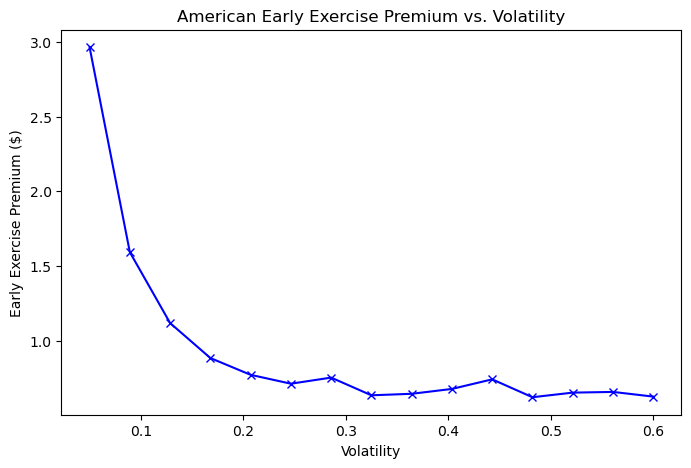

In [13]:
sigma_values = np.linspace(0.05, 0.6, 15)                               #generated 15 equally spaced volatilities from .05 to .6

am_p = []                                                               #make empty lists for American, then European prices
euro_p = []

for vol in sigma_values:                                                #for each volatility, store the american put price and european put price
    am_p.append(LSM_put(S0, K, T, r, vol, n_steps, n_simulations))      #found from LSM and Black-Scholes formula
    euro_p.append(black_scholes_put(S0, K, T, r, vol))

prem = np.array(am_p) - np.array(euro_p)                                #find difference in each price

#neatly plot the American Early Excersise Premium vs. volatility to show the relationship between the two
plt.figure(figsize=(8,5))
plt.plot(sigma_values, prem, marker='x', color='blue')
plt.xlabel("Volatility")
plt.ylabel("Early Exercise Premium ($)")
plt.title("American Early Exercise Premium vs. Volatility")
plt.savefig('../images/early_exercise_premium.png', dpi=150, bbox_inches='tight')   #save plot
plt.show()

## Applying to Real Market Data

Everything up to this point has used predetermined parameters to demonstrate and verify all of the tested methods. Real market data is far messier and unpredictable.

Now that the methods were confirmed with the simple examples, this section applies them to actual data from the yfinance library.

For this test, NVIDIA's stock was picked due to its popularity and high trading volume. The current stock price was pulled from the most recent closing price.

Then, the historical volatility was computed using the past year's daily log returns (the natural log of the ratio of each day's closing price to the prior day's closing price). This value was then annualized using sqrt(252) (typical number of trading days in a year). This gives a volatility that is used later in this notebook.

In [14]:
ticker = "NVDA"                                                 #stock, picked NVIDIA for this example
stock = yf.Ticker(ticker)

S0_real = stock.history(period="1d")['Close'].iloc[-1]          #grabs current stock price at last close

hist = stock.history(period="1y")
log_returns = np.log(hist['Close'] / hist['Close'].shift(1))    #gets log of returns
sig_real = log_returns.std() * np.sqrt(252)                     #annualized volatility

print(f"Real {ticker} stock price: ${S0_real:.2f}")
print(f"Annualized {ticker} historical volatility: {sig_real:.2%}")

Real NVDA stock price: $225.97
Annualized NVDA historical volatility: 36.79%


The strike price is then found by rounding the stock price to the nearest five dollars. The time to expiration is initially estimated at roughly 3 months.

For the risk free rate, the 13 week Treasury Bill rate was pulled as its maturity is a close match for the time to expiration.

In [15]:
K_real = round(S0_real/5)*5         #Strike price rounded to nearest $5
T_real = 0.25                       #3 months to expiration

treasury = yf.Ticker("^IRX")        #tracks 13-week Treasury Bill rate
r_real = treasury.history(period="1d")['Close'].iloc[-1]/100    #grabs risk free rate as decimal

print(f"Live risk-free rate: {r_real:.2%}")

Live risk-free rate: 3.70%


The fair prices of this NVDA put were then estimated using both the Black-Scholes formula and a Monte Carlo simulation (the same as the prior checks in the notebook). These act as a baseline before the time, volatility, and stirke price are refined to get a better live estimate.

In [16]:
bs_price_real = black_scholes_put(S0_real, K_real, T_real, r_real, sig_real)
mc_price_real = monte_carlo_put(S0_real, K_real, T_real, r_real, sig_real, n_sims=n_simulations)

print(f"Black-Scholes {ticker} European put option price: ${bs_price_real:.2f}")
print(f"Monte Carlo {ticker} European put option price: ${mc_price_real:.2f}")

Black-Scholes NVDA European put option price: $14.97
Monte Carlo NVDA European put option price: $14.91


The NVDA option expiration dates were pulled. From this list, a date of around 3-months out was manually selected (2026-11-20).

In [17]:
expirations = stock.options        #grab expriration dates and print them   
print(expirations)
exp = "2026-11-20"                 #select one about 3 months out

('2026-08-14', '2026-08-17', '2026-08-19', '2026-08-21', '2026-08-28', '2026-09-04', '2026-09-11', '2026-09-18', '2026-09-25', '2026-10-16', '2026-11-20', '2026-12-18', '2027-01-15', '2027-02-19', '2027-03-19', '2027-06-17', '2027-09-17', '2027-12-17', '2028-01-21', '2028-06-16', '2028-12-15')


Using this manually selected date, the time to expiration was refined from roughly 3 months (0.25 of a year) to an exact time (0.28 of a year). The Black-Scholes formula and Monte Carlo simulations were again used to see the effect this slight correction made to the estimated fair price for the put option.

In [18]:
today = datetime.date(2026, 8, 11)                      #grab date and get days to expiration, convert to years
expiration_date = datetime.date(2026, 11, 20)
days_left = (expiration_date - today).days
T_actual = days_left / 365

print(f"Days to expiration: {days_left}")               #print out results
print(f"Time to expiration (years): {T_actual:.2f}")

bs_price_real = black_scholes_put(S0_real, K_real, T_actual, r_real, sig_real)                      #use models to find price
mc_price_real = monte_carlo_put(S0_real, K_real, T_actual, r_real, sig_real, n_sims=500_000)

print(f"Black-Scholes price: ${bs_price_real:.2f}")
print(f"Monte Carlo price:   ${mc_price_real:.2f}")

Days to expiration: 101
Time to expiration (years): 0.28
Black-Scholes price: $15.71
Monte Carlo price:   $15.62


Using the confirmed expiration date, the live calls and puts were pulled. From the puts, the nearest strike price, last price, bid, ask, and implied volatility were printed.

In [19]:
opt_chain = stock.option_chain(exp)                             #get list of the puts and calls
puts = opt_chain.puts                                           #filter to puts

puts['strike_diff'] = abs(puts['strike'] - K_real)              #get strike difference from the prior rounded estimate and the actual strikes
closest_option = puts.sort_values('strike_diff').iloc[0]        #sort and choose the closest strike price

print(closest_option[['strike', 'lastPrice', 'bid', 'ask', 'impliedVolatility']])   #print the closest option's details

strike                  225.0
lastPrice               17.25
bid                      17.1
ask                      17.4
impliedVolatility    0.380255
Name: 35, dtype: object


For easier reference, the strike, last price, bid, ask, and implied volatility of the selected put were stored as variables.

In [20]:
mark_K = closest_option['strike']                           #store closest options parameters
mark_last_p = closest_option['lastPrice']
mark_bid = closest_option['bid']
mark_ask = closest_option['ask']
mark_impl_vol = closest_option['impliedVolatility']

print(f"Market Strike: ${mark_K}")                          #print values
print(f"Market Last Price: ${mark_last_p:.2f}")
print(f"Market bid/ask: ${mark_bid:.2f}/${mark_ask:.2f}")
print(f"Market Implied Volatility: {mark_impl_vol:.2%}")

Market Strike: $225.0
Market Last Price: $17.25
Market bid/ask: $17.10/$17.40
Market Implied Volatility: 38.03%


The three pricing methods are called, this time using the market's strike price instead of a rounded estimate. The results confirm that the Monte Carlo price converges to the Black-Scholes price, and that the European put has a lower fair price than the American put. All three models, depending on the day, vary from around $1.40-$1.80 below the real last traded price. This is explored in the next section.

Note: The exact prices shown vary from when this notebook is run since they are based on the current live data.

In [21]:
bs_price_mark_values = black_scholes_put(S0_real, mark_K, T_actual, r_real, sig_real)                               #calculate prices using replaced market parameters
mc_price_mark_values = monte_carlo_put(S0_real, mark_K, T_actual, r_real, sig_real, n_sims=n_simulations)
lsm_price_mark_values = LSM_put(S0_real, mark_K, T_actual, r_real, sig_real, n_steps=50, n_sims=n_simulations)


print(f"Black-Scholes price (market values): ${bs_price_mark_values:.2f}")      #print results
print(f"Monte Carlo price (market values):   ${mc_price_mark_values:.2f}")
print(f"LSM price (market values): ${lsm_price_mark_values:.2f}")
print(f"Last traded price: ${mark_last_p:.2f}")

Black-Scholes price (market values): $15.71
Monte Carlo price (market values):   $15.66
LSM price (market values): $15.88
Last traded price: $17.25


Finally, the market's implied volatility was used in place of the historical volatility, effectively raising both estimates to within about a dollar of the real market price. This shows the significance of using the most current, accurate data available.

The remaining gap can be the result of a variety of factors. The bid-ask spread (the last traded price may not exactly mirror the current live price) and dividends are both examples of this. Both would drive the value of the put up but are not accounted for in this notebook's pricing model.

In [22]:
bs_price_iv = black_scholes_put(S0_real, mark_K, T_actual, r_real, closest_option['impliedVolatility'])                     #calculate BS and print
print(f"Black-Scholes put using market IV:  ${bs_price_iv:.2f}")

mc_price_iv = monte_carlo_put(S0_real, mark_K, T_actual, r_real, closest_option['impliedVolatility'], n_sims=100_000)        #calculates MC and print
print(f"Monte Carlo put using market IV:    ${mc_price_iv:.2f}")

lsm_price_iv = LSM_put(S0_real, mark_K, T_actual, r_real, closest_option['impliedVolatility'], n_steps=50, n_sims=100_000)   #calculate LSM and print
print(f"LSM put using market IV:            ${lsm_price_iv:.2f}")

print(f"Market last traded price:           ${mark_last_p:.2f}")                                                            #print market last traded price


Black-Scholes put using market IV:  $16.29
Monte Carlo put using market IV:    $16.27
LSM put using market IV:            $16.46
Market last traded price:           $17.25
